# Évaluer une classification : métriques, seuils et validation

**Objectifs observables (90–120 min).** À la fin, vous pourrez calculer précision, rappel et F1 à partir d'une matrice de confusion, tracer comment un seuil déplace les faux positifs et les faux négatifs, choisir une métrique en fonction d'un coût concret, et distinguer validation et test final.

**Prérequis :** split stratifié, régression logistique, pipeline scikit-learn. Les données ci-dessous sont fournies par scikit-learn à des fins pédagogiques. Elles ne conviennent pas à une décision médicale.

## 1. Une classification binaire et sa baseline

Le dataset breast_cancer est intégré à scikit-learn. Dans cette leçon, la classe 1 est la classe positive fournie par le jeu ; ce choix pédagogique n'a aucune portée de diagnostic. On fait un split stratifié, puis on déclare deux candidats. Le test reste inutilisé jusqu'à la section finale.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, precision_recall_curve, average_precision_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=21)
baseline = DummyClassifier(strategy='most_frequent')
model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                      LogisticRegression(max_iter=2_000))
print('Observations train :', len(x_train), '| observations test gardées à part :', len(x_test))


## 2. Matrice de confusion : des comptes aux métriques

Une prédiction binaire produit quatre comptes. Lignes = classe réelle ; colonnes = classe prédite. En prenant **1 comme classe positive**, la précision est $TP/(TP+FP)$, le rappel $TP/(TP+FN)$, et $F1=2PR/(P+R)$. L'accuracy est $(TP+TN)/N$ : elle peut être trompeuse si la classe positive est rare.

**Exemple numérique.** Sur 100 observations, imaginons $TP=8$, $FP=2$, $FN=4$ et $TN=86$. L'accuracy vaut 94 %, mais le rappel vaut seulement $8/12=67$ %. Quel résultat serait plus important si rater un cas positif coûte cher ?

In [ ]:
toy_counts = {'TN': 86, 'FP': 2, 'FN': 4, 'TP': 8}
toy_precision = toy_counts['TP'] / (toy_counts['TP'] + toy_counts['FP'])
toy_recall = toy_counts['TP'] / (toy_counts['TP'] + toy_counts['FN'])
toy_f1 = 2 * toy_precision * toy_recall / (toy_precision + toy_recall)
toy_accuracy = (toy_counts['TP'] + toy_counts['TN']) / sum(toy_counts.values())
print({name: round(value, 3) for name, value in {'accuracy': toy_accuracy, 'precision': toy_precision, 'recall': toy_recall, 'F1': toy_f1}.items()})

## 3. Le seuil déplace les types d'erreurs

La probabilité estimée est convertie en classe par score supérieur ou égal au seuil. Baisser le seuil signale davantage d'observations : en général, les faux négatifs baissent et les faux positifs augmentent. Le compromis dépend du coût de ces erreurs.

Pour examiner les seuils, on extrait une validation du train. Les courbes et les métriques de cette section utilisent seulement cette validation. Pour le bilan final, le seuil 0,5 est fixé avant tout accès au test ; il ne représente pas un choix clinique.

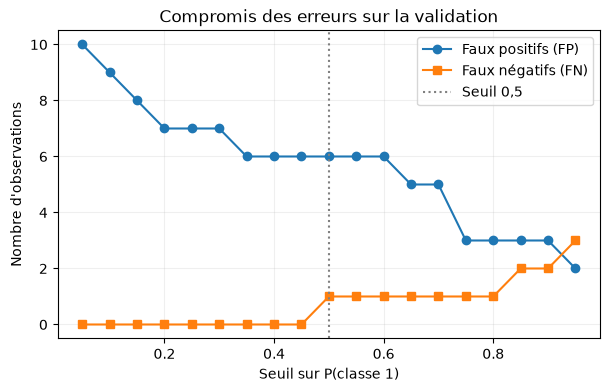

In [ ]:
from sklearn.base import clone

subtrain_x, validation_x, subtrain_y, validation_y = train_test_split(
    x_train, y_train, test_size=0.25, stratify=y_train, random_state=21
)
validation_model = clone(model).fit(subtrain_x, subtrain_y)
validation_scores = validation_model.predict_proba(validation_x)[:, 1]
threshold_grid = np.linspace(0.05, 0.95, 19)
fp_counts, fn_counts = [], []
for decision_threshold in threshold_grid:
    proposed = (validation_scores >= decision_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(validation_y, proposed, labels=[0, 1]).ravel()
    fp_counts.append(fp)
    fn_counts.append(fn)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(threshold_grid, fp_counts, marker='o', label='Faux positifs (FP)')
ax.plot(threshold_grid, fn_counts, marker='s', label='Faux négatifs (FN)')
ax.axvline(0.5, color='gray', linestyle=':', label='Seuil 0,5')
ax.set(xlabel='Seuil sur P(classe 1)', ylabel="Nombre d'observations", title="Compromis des erreurs sur la validation")
ax.legend(); ax.grid(alpha=0.2)
plt.show()
print('Le seuil approprié dépend du coût réel de FP et FN ; aucun seuil clinique n’est proposé.')

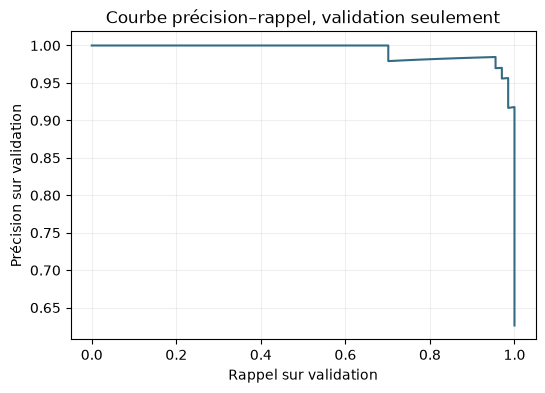

In [ ]:
for threshold in [0.3, 0.5, 0.7]:
    proposed = (validation_scores >= threshold).astype(int)
    print(f'seuil={threshold:.1f} validation precision={precision_score(validation_y, proposed):.3f} '
          f'recall={recall_score(validation_y, proposed):.3f}')
precision_values, recall_values, _ = precision_recall_curve(validation_y, validation_scores)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall_values, precision_values, color='#346b82')
ax.set(xlabel='Rappel sur validation', ylabel='Précision sur validation',
       title='Courbe précision–rappel, validation seulement')
ax.grid(alpha=0.2)
plt.show()
print('Average precision validation :',
      round(average_precision_score(validation_y, validation_scores), 3))
final_threshold = 0.5


## 4. Validation croisée et variabilité

La validation croisée répète entraînement et validation sur plusieurs partitions de `x_train`; la pipeline complète est réajustée dans chaque fold. Cela empêche l'imputation et le scaling d'apprendre sur les observations de validation. L'écart entre folds décrit une partie de l'instabilité, mais cinq folds issus du même jeu ne représentent pas toutes les populations futures. Une comparaison statistique sérieuse utilise les mêmes folds pour les deux modèles et tient compte de cette dépendance.

### Schéma — cinq validations dans le train, un test final

Chaque ligne est un entraînement distinct : les quatre blocs bleus ajustent toute la pipeline et le bloc orange mesure son score de validation. La position du bloc orange change à chaque fold. On compare les candidats avec ces scores, puis on réajuste celui qui a été retenu sur l'ensemble du train. Le test n'intervient qu'après cette décision.

**Limite :** le schéma suppose des observations indépendantes et ne montre ni groupes ni ordre temporel. Les scores des folds ne sont pas indépendants. Une validation croisée sur un seul dataset ne garantit pas la performance future.

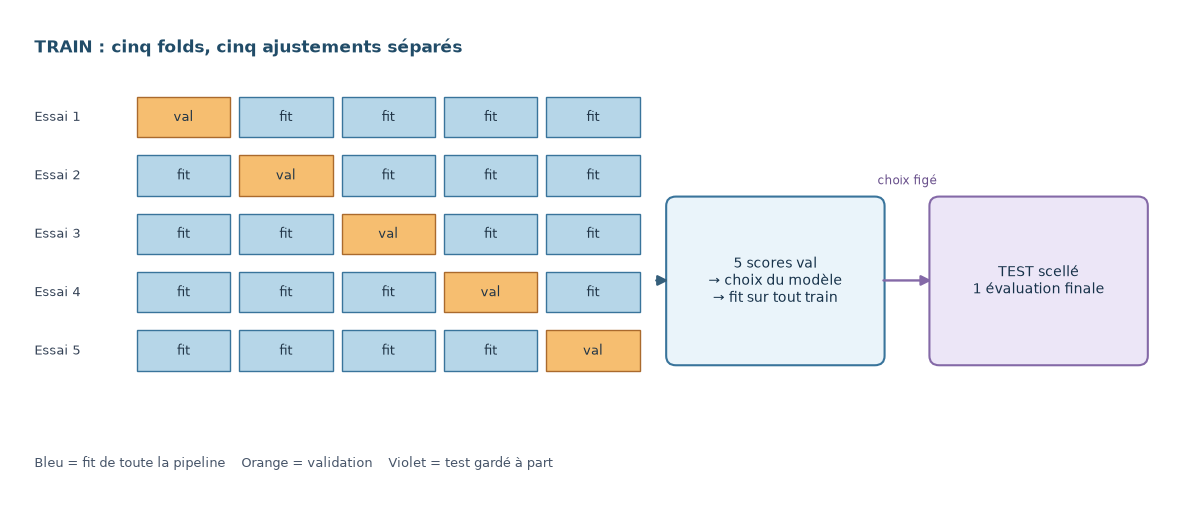

In [ ]:
from matplotlib.patches import Rectangle, FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 5.2))
ax.set(xlim=(0, 12), ylim=(0, 5.2))
ax.axis('off')
fig.patch.set_facecolor('white')
ax.text(0.25, 4.75, 'TRAIN : cinq folds, cinq ajustements s\u00e9par\u00e9s',
        fontsize=12, weight='bold', color='#214c68')
for fold in range(5):
    y = 3.85 - fold * 0.62
    ax.text(0.25, y + 0.21, f'Essai {fold + 1}',
            va='center', fontsize=9.5, color='#334155')
    for part in range(5):
        is_validation = fold == part
        x = 1.3 + part * 1.05
        ax.add_patch(Rectangle((x, y), 0.96, 0.43,
                     facecolor='#f6be70' if is_validation else '#b6d6e8',
                     edgecolor='#aa6a2d' if is_validation else '#39749b',
                     linewidth=1))
        ax.text(x + 0.48, y + 0.215, 'val' if is_validation else 'fit',
                ha='center', va='center', fontsize=9, color='#213547')

def cv_box(x, y, width, height, label, fill, border):
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                 boxstyle='round,pad=0.12,rounding_size=0.1',
                 linewidth=1.5, facecolor=fill, edgecolor=border))
    ax.text(x + width / 2, y + height / 2, label,
            ha='center', va='center', fontsize=10, color='#17324a')

cv_box(6.85, 1.55, 2.0, 1.55, '5 scores val\n\u2192 choix du mod\u00e8le\n\u2192 fit sur tout train',
       '#eaf4fa', '#39749b')
cv_box(9.55, 1.55, 2.0, 1.55, 'TEST scell\u00e9\n1 \u00e9valuation finale',
       '#ece6f7', '#8469a7')
ax.add_patch(FancyArrowPatch((6.6, 2.33), (6.78, 2.33),
             arrowstyle='-|>', mutation_scale=15, linewidth=1.7, color='#355f7b'))
ax.add_patch(FancyArrowPatch((8.93, 2.33), (9.48, 2.33),
             arrowstyle='-|>', mutation_scale=15, linewidth=1.7, color='#8469a7'))
ax.text(9.2, 3.35, 'choix fig\u00e9', ha='center', fontsize=8.5, color='#684f8b')
ax.text(0.25, 0.35,
        'Bleu = fit de toute la pipeline    Orange = validation    Violet = test gard\u00e9 \u00e0 part',
        fontsize=9.5, color='#475569')
plt.tight_layout()
plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)
fold_scores = cross_val_score(model, x_train, y_train, cv=cv,
                              scoring='average_precision')
baseline_fold_scores = cross_val_score(baseline, x_train, y_train, cv=cv,
                                       scoring='average_precision')
selected_name = 'pipeline logistique' if fold_scores.mean() > baseline_fold_scores.mean() else 'baseline'
selected_model = model if selected_name == 'pipeline logistique' else baseline
print('AP pipeline par fold :', fold_scores.round(3))
print('AP baseline par fold :', baseline_fold_scores.round(3))
print('Modèle retenu sur validation croisée :', selected_name)


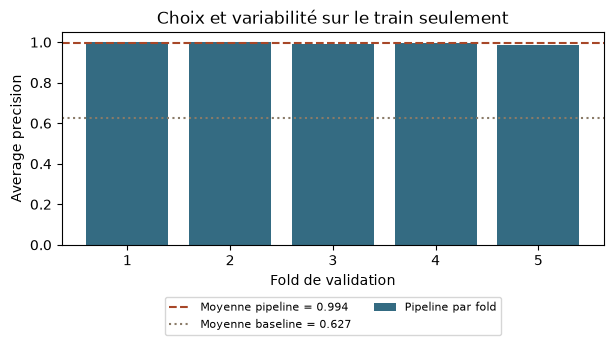

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(range(1, len(fold_scores) + 1), fold_scores,
       color='#346b82', label='Pipeline par fold')
ax.axhline(fold_scores.mean(), color='#a74728', linestyle='--',
           label=f'Moyenne pipeline = {fold_scores.mean():.3f}')
ax.axhline(baseline_fold_scores.mean(), color='#8a7b68', linestyle=':',
           label=f'Moyenne baseline = {baseline_fold_scores.mean():.3f}')
ax.set(xlabel='Fold de validation', ylabel='Average precision', ylim=(0, 1.05),
       title='Choix et variabilité sur le train seulement')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8)
fig.subplots_adjust(bottom=0.32)
plt.show()


## 5. Évaluation finale sur le test et analyse des erreurs

Le candidat est choisi par validation croisée et le seuil 0,5 a été fixé sur le train. On ajuste maintenant le candidat sur tout le train, puis on ouvre le test une seule fois pour calculer les métriques et examiner les erreurs. Ces résultats ne servent plus à changer le modèle ou le seuil. Une métrique résume un groupe d'exemples ; il faut aussi inspecter la provenance et la représentativité des données.

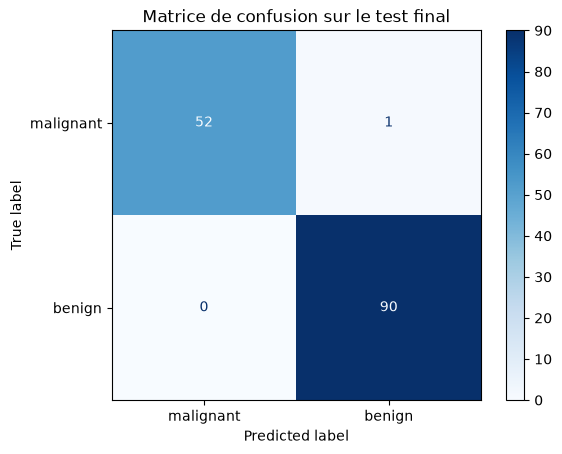

In [ ]:
from sklearn.base import clone

final_model = clone(selected_model).fit(x_train, y_train)
test_probability = final_model.predict_proba(x_test)[:, 1]
test_prediction = (test_probability >= final_threshold).astype(int)
cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(
    cmap='Blues', values_format='d')
plt.title('Matrice de confusion sur le test final')
plt.show()
print('Modèle évalué :', selected_name, '| seuil fixé :', final_threshold)
print('Accuracy :', round(accuracy_score(y_test, test_prediction), 3))
print('Precision :', round(precision_score(y_test, test_prediction), 3))
print('Recall :', round(recall_score(y_test, test_prediction), 3))
print('F1 :', round(f1_score(y_test, test_prediction), 3))
print('Average precision :', round(average_precision_score(y_test, test_probability), 3))


In [ ]:
error_table = x_test.copy()
error_table['actual'] = y_test
error_table['predicted'] = test_prediction
error_table['probability_class_1'] = test_probability
misclassified = error_table[error_table['actual'] != error_table['predicted']]
print('Nombre d’erreurs :', len(misclassified))
misclassified[['actual', 'predicted', 'probability_class_1']].head()

## À retenir, limites et pratique

- Choisir la classe positive explicitement et relier chaque métrique au type d'erreur qu'elle compte.
- Fixer les transformations et les paramètres sur train/validation ; évaluer ensuite une fois sur test.
- Une courbe PR mesure un classement, sans fixer à elle seule un coût d'erreur acceptable.
- Si plusieurs lignes viennent d'une même personne ou d'une série temporelle, adapter le split par groupe ou par temps.

**Exercices.** Refaire à la main le calcul numérique. Sur une validation seulement, comparer deux seuils avec un coût inventé `5×FN + FP`; expliquer pourquoi ce coût reflète une application précise. Voir [`05_evaluation.ipynb`](../../exercises/intermediate/05_evaluation.ipynb).